In [2]:
# General imports 
import os 
import re
import numpy as np
import pandas as pd
from pathlib import Path
import scipy.stats as stats 
from skimage import measure
import matplotlib.pyplot as plt
import math

# Pynwb imports
from hdmf_zarr import NWBZarrIO
from nwbwidgets import nwb2widget

import sys
# Add the directory that contains the 'bci' folder
sys.path.insert(0, '/code/src/')  # Note: changed to /code/src/ not /code/src/bci/

# Now these imports should work
from bci.loaders import load
from bci.processing import processing

# Functions that I am loading here but will eventually put in a separate .py file

In [3]:
def photostim_prepost_frames(epoch_table):
    epoch_table['duration'] = epoch_table.stop_time - epoch_table.start_time
    
    # Define the stimulus names we're looking for
    photo_stimuli = ['photostim', 'photostim_post']
    relevant_epochs = epoch_table[epoch_table['stimulus_name'].isin(photo_stimuli)].copy()
    relevant_epochs['duration'] = relevant_epochs.stop_time - relevant_epochs.start_time
    
    # Set stimulus_name as index for direct access
    indexed_epochs = relevant_epochs.set_index('stimulus_name')
    
    # Now you can directly access by stimulus name and convert to integers
    photostim_pre_start = int(indexed_epochs.loc['photostim'].start_frame)
    photostim_pre_stop = int(indexed_epochs.loc['photostim'].stop_frame)
    photostim_post_start = int(indexed_epochs.loc['photostim_post'].start_frame)
    photostim_post_stop = int(indexed_epochs.loc['photostim_post'].stop_frame)
    
    return photostim_pre_start, photostim_pre_stop, photostim_post_start, photostim_post_stop

In [4]:
def get_roi_centroids(valid_roi_table):
    '''
    Iterate through the image masks in the ROI table, 
    get the indices corresponding to each ROI, 
    then take the average to get the x and y locations of the cell centroid. 
    
    Returns an array with dimensions (n_cells, xy_position)
    '''
    centroids = []
    for mask in valid_roi_table['image_mask']:
        ys, xs = np.where(mask)
        x = np.mean(xs)
        y = np.mean(ys)
        centroids.append((x, y))
    return np.array(centroids)

In [5]:
def correlation_prepost_bci(dff_traces, photostim_pre_start, photostim_pre_stop, 
                           photostim_post_start, photostim_post_stop, valid_roi_table):
    import numpy as np
    import matplotlib.pyplot as plt
    from scipy import stats
    
    # Index into the dff traces array to limit to the relevant time points
    dff_pre = dff_traces[photostim_pre_start:photostim_pre_stop, :]
    dff_pre = dff_pre.T
    dff_post = dff_traces[photostim_post_start:photostim_post_stop, :]
    dff_post = dff_post.T
                            
    # Limit dff traces for photostimulation activity period before the task to valid ROIs
    dff_pre = dff_pre[valid_roi_table.index.values, :]
    print(f"dff_pre shape: {dff_pre.shape}")
    
    # Limit dff traces for photostimulation activity period after the task to valid ROIs
    dff_post = dff_post[valid_roi_table.index.values, :]
    print(f"dff_post shape: {dff_post.shape}")
    
    # Calculate correlation matrices
    correlations_pre = np.corrcoef(dff_pre)
    correlations_post = np.corrcoef(dff_post)
    
    # Keep only upper triangular part (avoid duplicate pairs and diagonal)
    correlations_pre = np.triu(correlations_pre, k=1)
    correlations_post = np.triu(correlations_post, k=1)
    
    # Statistical comparison
    t, p_val = stats.ttest_ind(correlations_pre.flatten(), correlations_post.flatten())
    print(f"T-test p-value: {p_val}")
    
    # Plot both distributions
    plt.figure(figsize=(10, 6))
    plt.hist(correlations_pre.flatten(), bins=100, color='green', label='pre', histtype='step')
    plt.hist(correlations_post.flatten(), bins=100, color='purple', label='post', histtype='step')
    plt.title('Correlations before and after BCI learning, p=' + str(np.round(p_val, 5)))
    plt.xlabel('Correlation')
    plt.ylabel('# cell pairs')
    plt.xlim(-0.1, 0.1)
    plt.legend()
    plt.show()
    
    return correlations_pre, correlations_post, p_val

# Carry on

In [6]:
metadata = load.load_filtered_metadata()

In [7]:
# Select a specific subject
target_subject_id = 754303 

In [8]:
# Filter metadata for that subject
subject_sessions754303  = metadata[metadata['subject_id'] == target_subject_id]

In [9]:
sesh_zero = subject_sessions754303['name'].values[1]

In [11]:
full_session_data = load.load_session_data(sesh_zero)

BCI data directory: /data/brain-computer-interface

Session directory: /data/brain-computer-interface/single-plane-ophys_754303_2025-01-23_19-48-32_processed_2025-08-08_15-29-29

NWB file: single-plane-ophys_754303_2025-01-23_19-48-32_behavior_nwb
NWB path: /data/brain-computer-interface/single-plane-ophys_754303_2025-01-23_19-48-32_processed_2025-08-08_15-29-29/single-plane-ophys_754303_2025-01-23_19-48-32_behavior_nwb


/opt/conda/lib/python3.10/site-packages/hdmf/spec/namespace.py:535: UserWarning: Ignoring cached namespace 'core' version 2.7.0 because version 2.8.0 is already loaded.
  warn("Ignoring cached namespace '%s' version %s because version %s is already loaded."


All threshold files for mouse 754303: ['single-plane-ophys_754303_2025-01-27', 'single-plane-ophys_754303_2025-01-23', 'single-plane-ophys_754303_2025-01-29', 'single-plane-ophys_754303_2025-01-31', 'single-plane-ophys_754303_2025-02-03']

Found threshold file at: /data/bci-thresholds/single-plane-ophys_754303_2025-01-23
total difference in dataframes: 4


In [12]:
full_session_data.keys()

dict_keys(['nwb_file', 'epoch_table', 'dff_traces', 'roi_table', 'frame_rate', 'bci_trials', 'thresholds'])

In [13]:
photostim = full_session_data['nwb_file'].stimulus["PhotostimTrials"].to_dataframe()

In [15]:
# Separate the two phases
photostim_trials = photostim[photostim['stimulus_name'] == 'photostim'].copy()
photostim_post_trials = photostim[photostim['stimulus_name'] == 'photostim_post'].copy()

print(f"Pre-learning trials: {len(photostim_trials)}")
print(f"Post-learning trials: {len(photostim_post_trials)}")

# Reset indices to match trial numbers
photostim_trials = photostim_trials.reset_index(drop=True)
photostim_post_trials = photostim_post_trials.reset_index(drop=True)

print("Ready to compare trial pairs!")

Pre-learning trials: 1008
Post-learning trials: 1078
Ready to compare trial pairs!


In [16]:
# Find neurons that were stimulated in both phases
pre_neurons = set(photostim_trials['closest_roi'])
post_neurons = set(photostim_post_trials['closest_roi'])
common_neurons = pre_neurons.intersection(post_neurons)

print(f"Neurons stimulated in both phases: {len(common_neurons)}")
print(f"Example neurons: {list(common_neurons)[:10]}")

Neurons stimulated in both phases: 49
Example neurons: [132, 7, 1547, 12, 139, 2574, 18, 19, 2713, 665]


In [18]:
# Clean the data (remove NaN neurons)
nan_neurons = np.isnan(dff_traces).any(axis=0)
valid_neurons = ~nan_neurons
valid_neuron_indices = np.where(valid_neurons)[0]
dff_traces_clean = dff_traces[:, valid_neuron_indices]

# Get valid ROI table
valid_roi_table, cn_index = processing.filter_somas(data=data)

# Define correlation function
def correlation_prepost_stimulation(dff_traces_clean, pre_trials, post_trials, valid_roi_table):
    # Combine all pre-learning trials
    pre_data_list = []
    for _, trial in pre_trials.iterrows():
        trial_dff = dff_traces_clean[trial['start_frame']:trial['stop_frame'], :].T
        pre_data_list.append(trial_dff)
    dff_pre = np.concatenate(pre_data_list, axis=1)
    
    # Combine all post-learning trials
    post_data_list = []
    for _, trial in post_trials.iterrows():
        trial_dff = dff_traces_clean[trial['start_frame']:trial['stop_frame'], :].T
        post_data_list.append(trial_dff)
    dff_post = np.concatenate(post_data_list, axis=1)
    
    # Filter to valid ROIs only
    dff_pre = dff_pre[valid_roi_table.index.values, :]
    dff_post = dff_post[valid_roi_table.index.values, :]
    
    # Calculate correlation matrices
    correlations_pre = np.corrcoef(dff_pre)
    correlations_post = np.corrcoef(dff_post)
    
    return correlations_pre, correlations_post


CN: [26]


In [21]:
# Run the analysis for all neurons
stimulated_neurons = list(common_neurons)
all_correlation_changes = {}

for i, target_neuron in enumerate(stimulated_neurons):
    print(f"Processing neuron {target_neuron} ({i+1}/{len(stimulated_neurons)})")
    
    pre_neuron_trials = photostim_trials[photostim_trials['closest_roi'] == target_neuron]
    post_neuron_trials = photostim_post_trials[photostim_post_trials['closest_roi'] == target_neuron]
    
    correlations_pre, correlations_post = correlation_prepost_stimulation(
        dff_traces_clean, pre_neuron_trials, post_neuron_trials, valid_roi_table
    )
    
    correlation_diff = correlations_post - correlations_pre
    upper_triangle = np.triu(correlation_diff, k=1)
    all_changes = upper_triangle[upper_triangle != 0]
    all_correlation_changes[target_neuron] = all_changes


Processing neuron 132 (1/49)


NameError: name 'pre_trials' is not defined

In [19]:
# Run the analysis for all neurons
stimulated_neurons = list(common_neurons)
all_correlation_changes = {}

for i, target_neuron in enumerate(stimulated_neurons):
   print(f"Processing neuron {target_neuron} ({i+1}/{len(stimulated_neurons)})")
   
   pre_neuron_trials = pre_trials[pre_trials['closest_roi'] == target_neuron]
   post_neuron_trials = post_trials[post_trials['closest_roi'] == target_neuron]
   
   correlations_pre, correlations_post, p_val = correlation_prepost_stimulation(
       dff_traces_clean, pre_neuron_trials, post_neuron_trials, target_neuron, show_plot=False)
   
   correlation_diff = correlations_post - correlations_pre
   upper_triangle = np.triu(correlation_diff, k=1)
   all_changes = upper_triangle[upper_triangle != 0]
   all_correlation_changes[target_neuron] = all_changes

# Create plots
#fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Combined histogram of all changes
#all_changes_combined = np.concatenate(list(all_correlation_changes.values()))
#ax1.hist(all_changes_combined, bins=100, alpha=0.7, color='gray')
#ax1.set_xlabel('Correlation Change (Post - Pre)')
#ax1.set_ylabel('Count')
#ax1.set_title('Distribution of All Correlation Changes')
#ax1.axvline(x=0, color='red', linestyle='--', alpha=0.7)

# Box plot for all neurons
#data_for_boxplot = [changes for changes in all_correlation_changes.values()]
#ax2.boxplot(data_for_boxplot)
#ax2.set_xlabel('Stimulated Neuron Index')
#ax2.set_ylabel('Correlation Change (Post - Pre)')
#ax2.set_title('Distribution Summary: All Neurons')
#ax2.axhline(y=0, color='red', linestyle='--', alpha=0.7)

# Show fewer x-axis labels
#neuron_ids = list(all_correlation_changes.keys())
#ax2.set_xticks(range(0, len(neuron_ids), 10))
#ax2.set_xticklabels([f'N{neuron_ids[i]}' for i in range(0, len(neuron_ids), 10)], rotation=45)

#plt.tight_layout()
#plt.show()

# Summary statistics
print(f"Total correlation changes analyzed: {len(all_changes_combined)}")
print(f"Mean change: {np.mean(all_changes_combined):.4f}")
print(f"Median change: {np.median(all_changes_combined):.4f}")
print(f"Standard deviation: {np.std(all_changes_combined):.4f}")

Processing neuron 132 (1/49)


NameError: name 'pre_trials' is not defined

# Correlation Matrix Graphs: Pre, Post, PrePost Diff

In [19]:
correlations_pre = np.triu(correlations_pre, k=1)
correlations_post = np.triu(correlations_post, k=1)
correlation_diff = np.triu(correlation_diff, k=1)

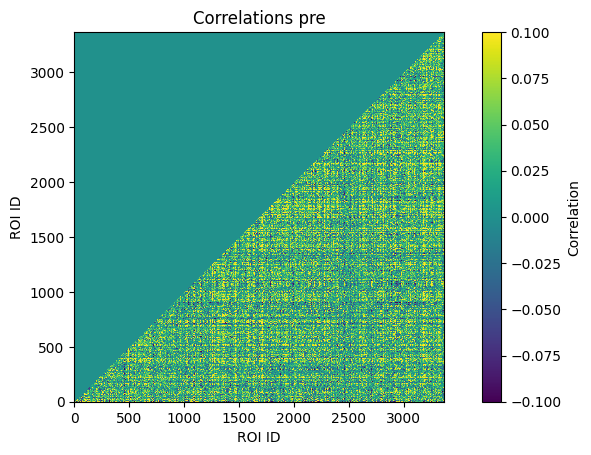

In [20]:
plt.pcolormesh(correlations_pre, cmap='viridis', vmin=-0.1, vmax=0.1)
plt.colorbar(label='Correlation')
plt.xlabel('ROI ID')
plt.ylabel('ROI ID')
plt.title('Correlations pre')
plt.axis('square')
plt.savefig('/code/scripts/miguel/Graphs/M754303 - S5:Corr_pre.png', dpi=300, bbox_inches='tight')

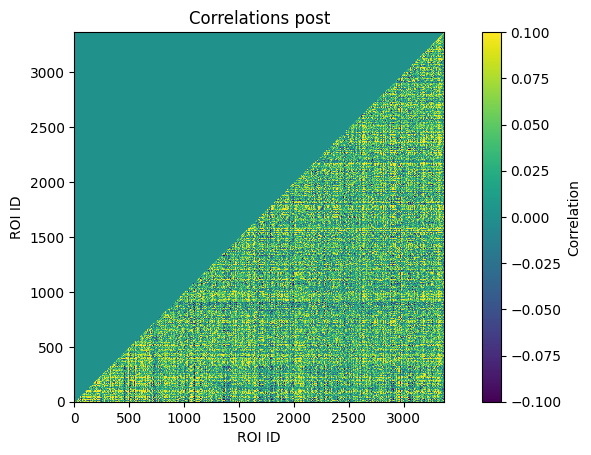

In [21]:
plt.pcolormesh(correlations_post, cmap='viridis', vmin=-0.1, vmax=0.1)
plt.colorbar(label='Correlation')
plt.xlabel('ROI ID')
plt.ylabel('ROI ID')
plt.title('Correlations post')
plt.axis('square')
plt.savefig('/code/scripts/miguel/Graphs/M754303 - S5:Corr_post.png', dpi=300, bbox_inches='tight')

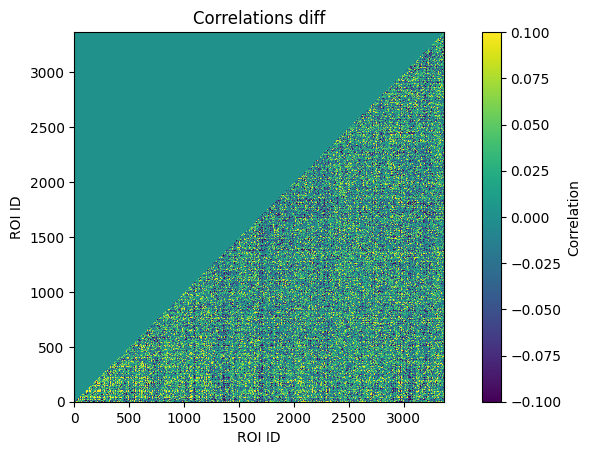

In [22]:
plt.pcolormesh(correlation_diff, cmap='viridis', vmin=-0.1, vmax=0.1)
plt.colorbar(label='Correlation')
plt.xlabel('ROI ID')
plt.ylabel('ROI ID')
plt.title('Correlations diff')
plt.axis('square')
plt.savefig('/code/scripts/miguel/Graphs/M754303 - S5:Corr_diff.png', dpi=300, bbox_inches='tight')

In [24]:
# Load your images
img1 = mpimg.imread('/code/scripts/miguel/Graphs/M754303 - S5:Corr_pre.png')
img2 = mpimg.imread('/code/scripts/miguel/Graphs/M754303 - S5:Corr_post.png')
img3 = mpimg.imread('/code/scripts/miguel/Graphs/M754303 - S5:Corr_diff.png')



# Create figure with subplots
fig, axes = plt.subplots(1, 3, figsize=(15, 10)) 

# Display images in specific order
axes[0].imshow(img1)
axes[0].set_title('Mouse 754303 - Session 3')
axes[0].axis('off')

axes[1].imshow(img2)
axes[1].set_title('Mouse 754303 - Session 3')
axes[1].axis('off')

axes[2].imshow(img3)
axes[2].set_title('Mouse 754303 - Session 3')
axes[2].axis('off')

#plt.tight_layout()

plt.savefig('/code/scripts/miguel/Graphs/M754303_S5_AllCorr.png', dpi=300, bbox_inches='tight')
plt.show()

NameError: name 'mpimg' is not defined

In [ ]:
stop

# End of Correlation Matrices

In [ ]:
# Calculate mean correlation change per neuron
mean_corr = np.mean(data_for_boxplot, axis=1)

# Calculate population statistics
pop_mean = np.mean(mean_corr)
pop_std = np.std(mean_corr)
threshold = 2 * pop_std

# Identify outlier neurons
outlier_neurons = np.abs(mean_corr - pop_mean) > threshold
outlier_count = np.sum(outlier_neurons)

print(f"Population mean: {pop_mean:.4f}")
print(f"Population std: {pop_std:.4f}")
print(f"2x std threshold: {threshold:.4f}")
print(f"Neurons beyond 2x std: {outlier_count}")
print(f"Outlier neuron indices: {np.where(outlier_neurons)[0]}")

In [ ]:
plt.figure(figsize=(10, 4))
plt.hist(mean_corr, bins=200, alpha=0.7, color='gray')
plt.axvline(pop_mean + threshold, color='red', linestyle='--', label='+2x std')
plt.axvline(pop_mean - threshold, color='red', linestyle='--', label='-2x std')
plt.axvline(pop_mean, color='blue', linestyle='-', label='Mean')
plt.xlabel('Mean Correlation Change per Neuron')
plt.ylabel('Number of Neurons')
plt.title('Distribution of Mean Correlation Changes')
plt.legend()
plt.savefig('/code/scripts/miguel/Graphs/M754303 - S5: mean_correlation_distribution.png', dpi=300, bbox_inches='tight')
# Save figure
#plt.savefig('/Graphs/mean_correlation_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

# Load your images
img1 = mpimg.imread('/code/scripts/miguel/Graphs/M754303 - S3: mean_correlation_distribution.png')
img2 = mpimg.imread('/code/scripts/miguel/Graphs/M754303 - S5: mean_correlation_distribution.png')
img3 = mpimg.imread('/code/scripts/miguel/Graphs/M754303 - S6: mean_correlation_distribution.png')
img4 = mpimg.imread('/code/scripts/miguel/Graphs/M754303 - S8: mean_correlation_distribution.png')
img5 = mpimg.imread('/code/scripts/miguel/Graphs/M754303 - S9: mean_correlation_distribution.png')


# Create figure with subplots
fig, axes = plt.subplots(2, 3, figsize=(15, 10))  # 2 rows, 3 columns

# Display images in specific order
axes[0, 0].imshow(img1)
axes[0, 0].set_title('Mouse 754303 - Session 3')
axes[0, 0].axis('off')

axes[0, 1].imshow(img2)
axes[0, 1].set_title('Mouse 754303 - Session 5')
axes[0, 1].axis('off')

axes[0, 2].imshow(img3)
axes[0, 2].set_title('Mouse 754303 - Session 6')
axes[0, 2].axis('off')

axes[1, 0].imshow(img4)
axes[1, 0].set_title('Mouse 754303 - Session 8')
axes[1, 0].axis('off')

axes[1, 1].imshow(img5)
axes[1, 1].set_title('Mouse 754303 - Session 9')
axes[1, 1].axis('off')

#plt.tight_layout()
plt.savefig('/code/scripts/miguel/Graphs/M754303_AllSessions.png', dpi=300, bbox_inches='tight')
plt.show()